# Midterm — Gambar Data Story

Visualisasi Data Lanjut (CAK7AGB4) · NIM 203012420009

Membaca `../datasets/tb_bersih.csv` (hasil `00_eksplorasi_data.ipynb`). Periode 2020–2025, 80 puskesmas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

FIG = Path("figure")
FIG.mkdir(exist_ok=True)

# Warna: sorotan, pembanding, konteks
BIRU, ORANYE, ABU = "#2a78d6", "#eb6834", "#c4c2bb"
TEKS, TEKS2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": "#d9d7d0", "axes.labelcolor": TEKS2,
    "xtick.color": TEKS2, "ytick.color": TEKS2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def nama(s):
    return s.str.replace("UPT ", "", regex=False).str.title()

In [2]:
df = pd.read_csv("../datasets/tb_bersih.csv")
P = list(range(2020, 2026))
pkm = df[(df["kategori"] == "Puskesmas") & df["tahun"].isin(P)]
t = pkm.groupby(["faskes", "tahun"])["kasus"].sum().unstack()
t.index = nama(t.index.to_series())
t["total"] = t[P].sum(axis=1)
t.shape

(80, 7)

## Gambar 1 — Klaim 1: kenaikan 2021–2024 di 74 dari 80 puskesmas

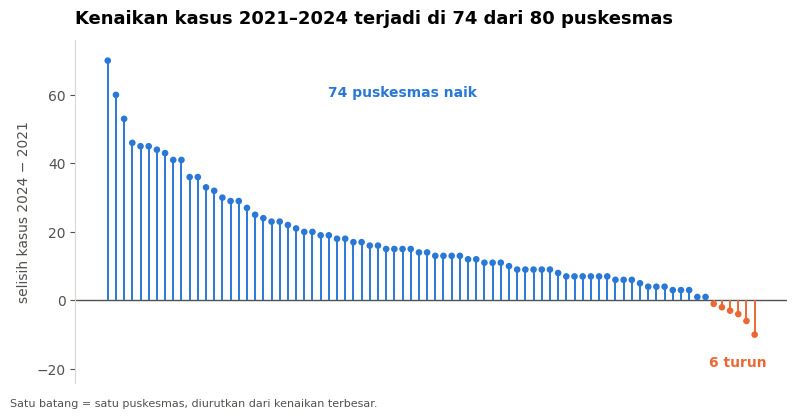

In [3]:
naik = t[2024] - t[2021]
urut1 = naik.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
x = range(len(urut1))
ax.axhline(0, color=TEKS2, lw=1)
ax.vlines(x, 0, urut1.values, color=[BIRU if v > 0 else ORANYE for v in urut1.values], lw=1.4)
ax.scatter(x, urut1.values, s=14, color=[BIRU if v > 0 else ORANYE for v in urut1.values], zorder=3)
ax.text(36, urut1.max() * 0.85, "74 puskesmas naik", color=BIRU, fontweight="bold", ha="center")
ax.text(77, urut1.min() - 6, "6 turun", color=ORANYE, fontweight="bold", ha="center", va="top")
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_ylabel("selisih kasus 2024 − 2021")
ax.set_ylim(urut1.min() - 14, urut1.max() + 6)
ax.set_title("Kenaikan kasus 2021–2024 terjadi di 74 dari 80 puskesmas", pad=12)
fig.text(0.01, 0.02, "Satu batang = satu puskesmas, diurutkan dari kenaikan terbesar.", color=TEKS2, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / "gambar1.png", dpi=200)
plt.show()

## Gambar 2 — Klaim 2: separuh kasus di 21 dari 80 puskesmas (bar terurut)

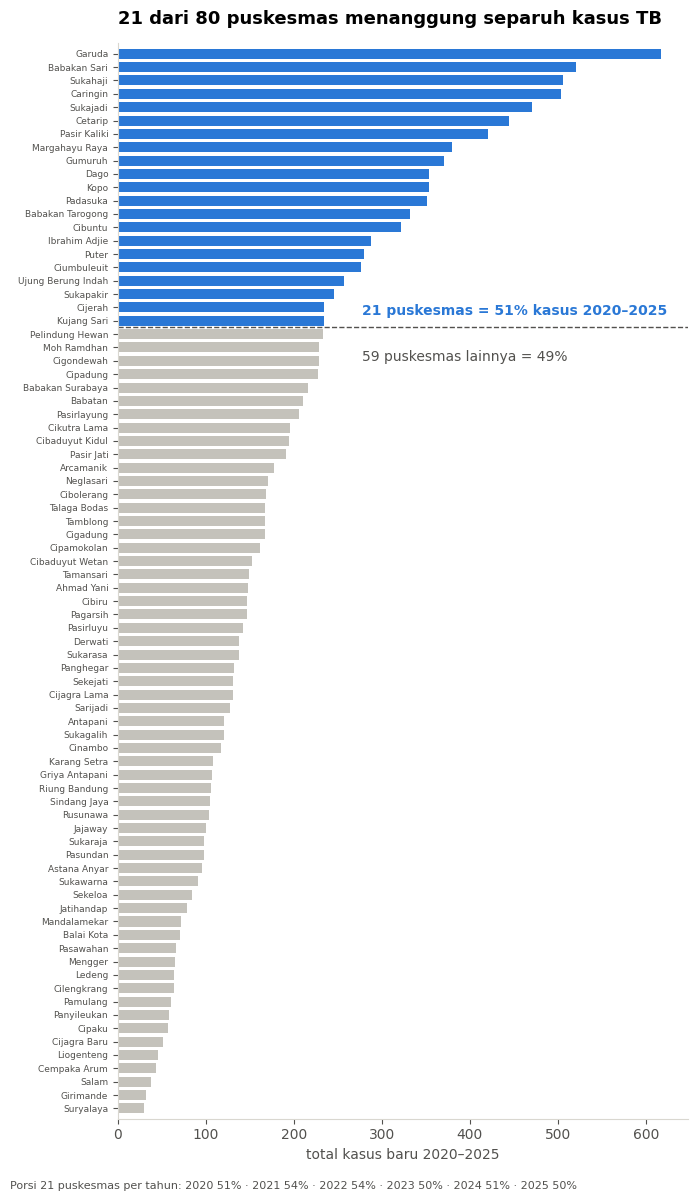

In [4]:
s = t["total"].sort_values(ascending=False)
top21 = s.index[:21]
porsi_tahun = (t.loc[top21, P].sum() / t[P].sum())

fig, ax = plt.subplots(figsize=(7, 12))
warna = [BIRU if n in top21 else ABU for n in s.index]
ax.barh(range(len(s)), s.values, color=warna, height=0.75)
ax.set_yticks(range(len(s)), s.index, fontsize=6.5)
ax.invert_yaxis()
ax.axhline(20.5, color=TEKS2, lw=1, ls="--")
ax.text(s.max() * 0.45, 19.8, f"21 puskesmas = {s[top21].sum() / s.sum():.0%} kasus 2020–2025", color=BIRU, fontweight="bold", ha="left", va="bottom")
ax.text(s.max() * 0.45, 22.2, f"59 puskesmas lainnya = {1 - s[top21].sum() / s.sum():.0%}", color=TEKS2, ha="left", va="top")
ax.set_xlabel("total kasus baru 2020–2025")
ax.set_title("21 dari 80 puskesmas menanggung separuh kasus TB", pad=14)
ax.margins(y=0.005)
fig.text(0.01, 0.005, "Porsi 21 puskesmas per tahun: " + " · ".join(f"{y} {v:.0%}" for y, v in porsi_tahun.items()), color=TEKS2, fontsize=8)
fig.tight_layout(rect=(0, 0.015, 1, 1))
fig.savefig(FIG / "gambar2.png", dpi=200)
plt.show()

## Gambar 3 — Klaim 3: 10 besar yang tetap sama dari tahun ke tahun

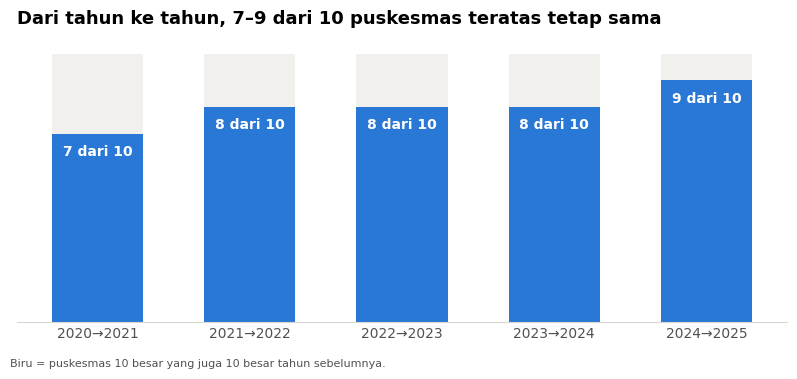

In [5]:
# Berapa dari 10 besar tahun ini yang sama dengan tahun sebelumnya
sama = pd.Series({f"{y - 1}→{y}": len(set(t[y - 1].nlargest(10).index) & set(t[y].nlargest(10).index)) for y in P[1:]})
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(sama)), sama.values, color=BIRU, width=0.6)
ax.bar(range(len(sama)), 10 - sama.values, bottom=sama.values, color="#f1f0ec", width=0.6)
for i, v in enumerate(sama.values):
    ax.text(i, v - 0.4, f"{v} dari 10", ha="center", va="top", color="white", fontweight="bold")
ax.set_xticks(range(len(sama)), sama.index)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.set_title("Dari tahun ke tahun, 7–9 dari 10 puskesmas teratas tetap sama", pad=12)
fig.text(0.01, 0.02, "Biru = puskesmas 10 besar yang juga 10 besar tahun sebelumnya.", color=TEKS2, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIG / "gambar3.png", dpi=200)
plt.show()

## Bump chart peringkat per tahun

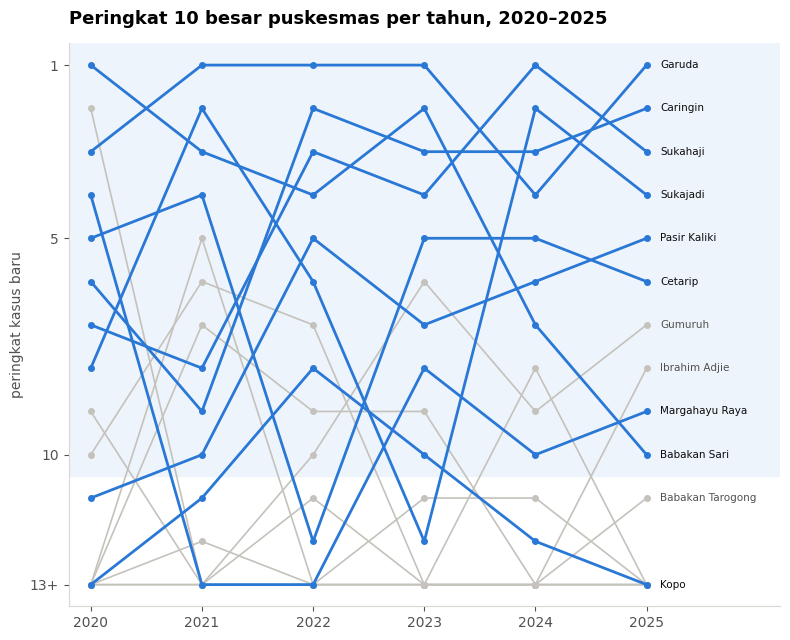

In [6]:
rank = t[P].rank(ascending=False, method="first")
top10_mana_saja = rank.index[(rank <= 10).any(axis=1)]
awal = t[[2020, 2021, 2022]].sum(axis=1).nlargest(10).index
akhir = t[[2023, 2024, 2025]].sum(axis=1).nlargest(10).index
tetap = awal.intersection(akhir)

fig, ax = plt.subplots(figsize=(8, 6.5))
for n in top10_mana_saja:
    r = rank.loc[n].clip(upper=13)
    w = BIRU if n in tetap else ABU
    ax.plot(P, r, color=w, lw=2 if w == BIRU else 1.2, marker="o", ms=4, zorder=3 if w == BIRU else 2)
    if rank.loc[n, 2025] <= 13:
        ax.text(2025.12, r[2025], n, color=TEKS if w == BIRU else TEKS2, fontsize=7.5, va="center")
ax.axhspan(0.5, 10.5, color="#eef4fc", zorder=0)
ax.set_yticks([1, 5, 10, 13], ["1", "5", "10", "13+"])
ax.set_ylim(13.5, 0.5)
ax.set_xticks(P)
ax.set_xlim(2019.8, 2026.2)
ax.set_ylabel("peringkat kasus baru")
ax.set_title("Peringkat 10 besar puskesmas per tahun, 2020–2025", pad=14)
fig.tight_layout()
fig.savefig(FIG / "gambar4.png", dpi=200)
plt.show()